# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv('data/cleaned_aviation_data.csv', low_memory=False)
df.shape

(66496, 23)

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
# Total.People is our proxy for passenger count aboard.
# Split at 20 people: below is "small" (typical GA/piston aircraft), at/above is "large" (airliner-scale).
small = df[df['Total.People'] < 20].copy()
large = df[df['Total.People'] >= 20].copy()

print(f'small aircraft accidents: {len(small)}')
print(f'large aircraft accidents: {len(large)}')

small aircraft accidents: 65277
large aircraft accidents: 1219


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

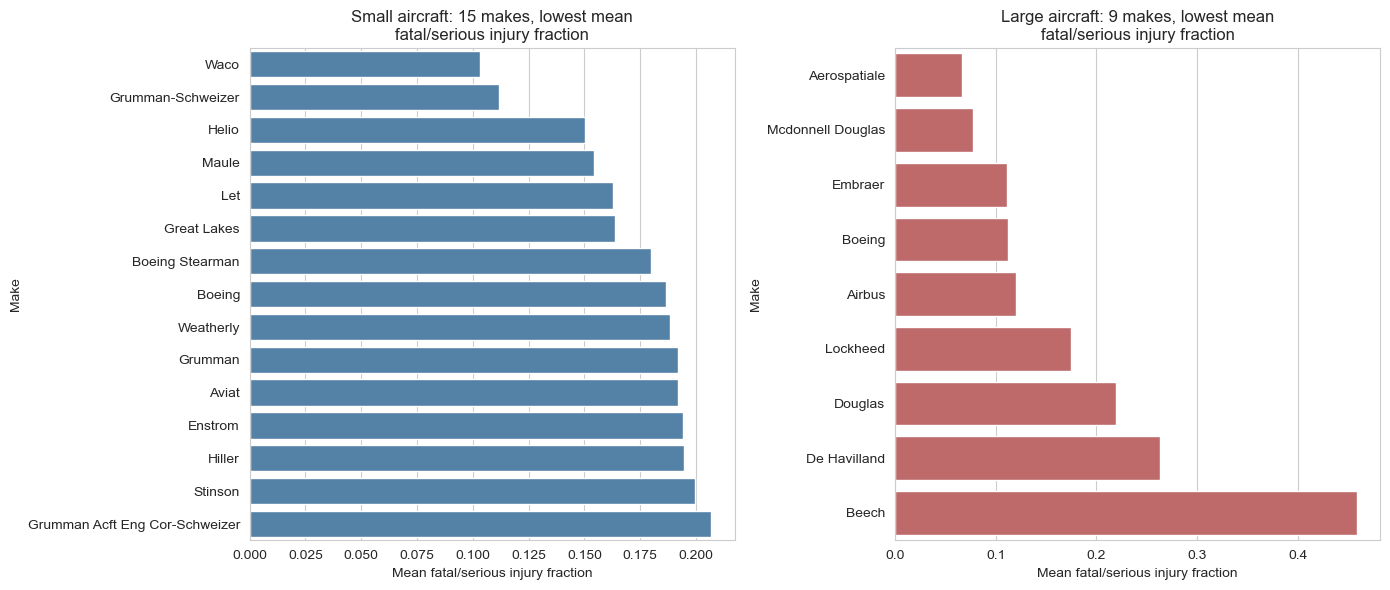

In [4]:
MIN_N = 10

def lowest_injury_makes(sub, n=15, min_n=MIN_N):
    g = sub.groupby('Make')['Fatal.Serious.Fraction'].agg(['mean', 'count'])
    return g[g['count'] >= min_n].sort_values('mean').head(n)

small_makes = lowest_injury_makes(small)
large_makes = lowest_injury_makes(large)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_makes['mean'], y=small_makes.index, ax=axes[0], color='steelblue')
axes[0].set_title('Small aircraft: 15 makes, lowest mean\nfatal/serious injury fraction')
axes[0].set_xlabel('Mean fatal/serious injury fraction')

sns.barplot(x=large_makes['mean'], y=large_makes.index, ax=axes[1], color='indianred')
axes[1].set_title(f'Large aircraft: {len(large_makes)} makes, lowest mean\nfatal/serious injury fraction')
axes[1].set_xlabel('Mean fatal/serious injury fraction')

plt.tight_layout()
plt.show()


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

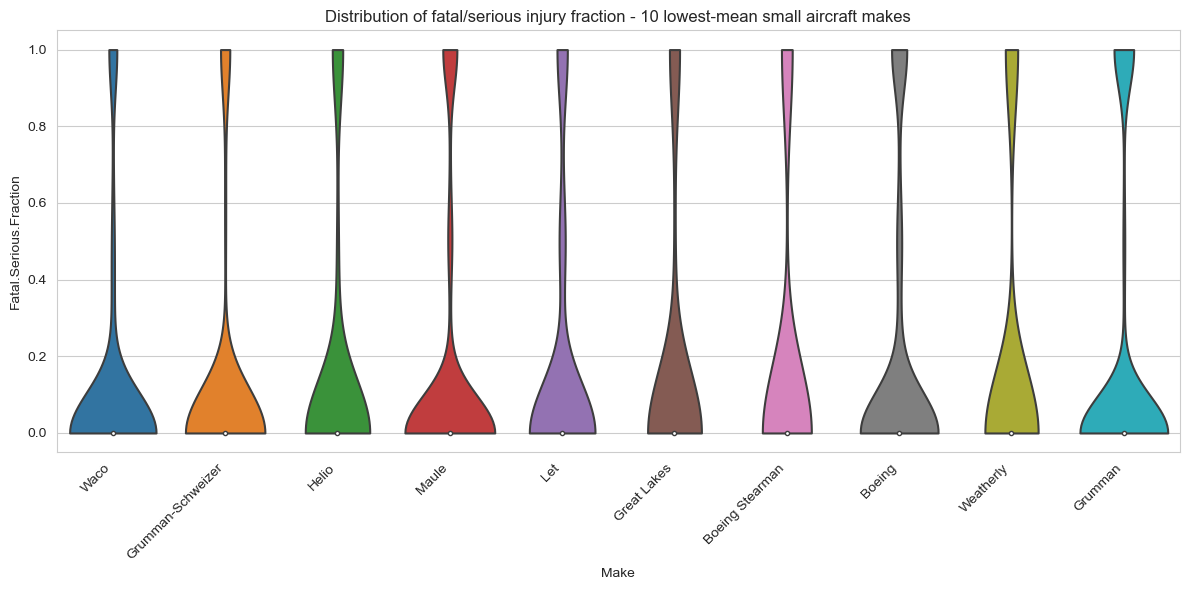

In [5]:
top10_small_makes = small_makes.head(10).index
small_top10 = small[small['Make'].isin(top10_small_makes)]

order = small_makes.head(10).index

plt.figure(figsize=(12, 6))
sns.violinplot(data=small_top10, x='Make', y='Fatal.Serious.Fraction', order=order, cut=0)
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of fatal/serious injury fraction - 10 lowest-mean small aircraft makes')
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

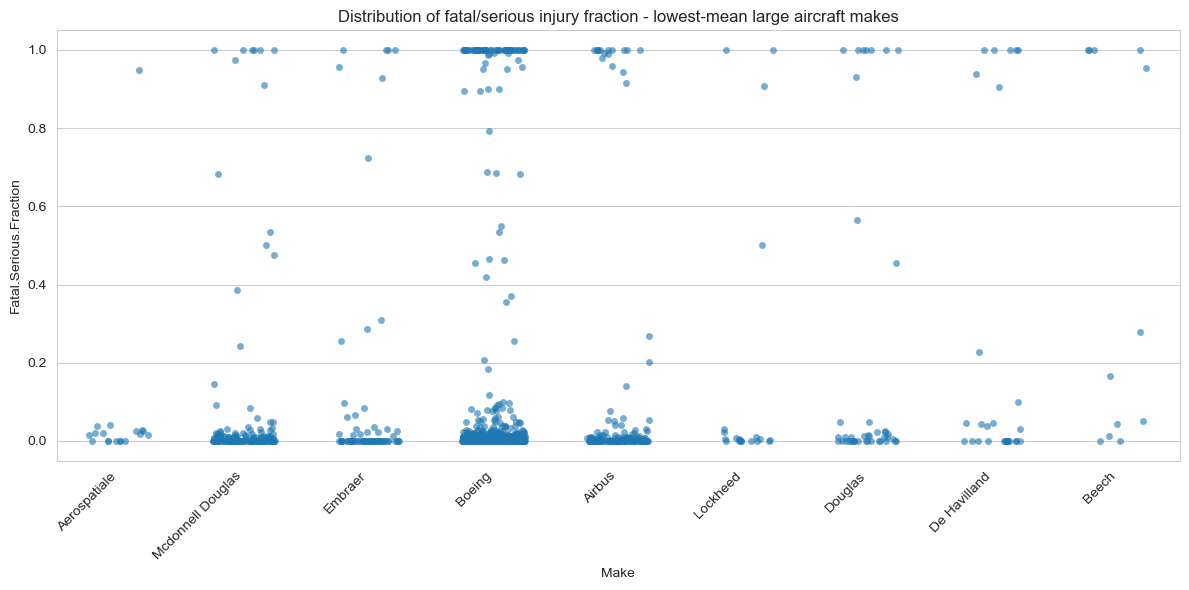

In [6]:
# only 9 large makes clear the min-sample bar, so "10 lowest" is every qualifying make here
top10_large_makes = large_makes.head(10).index
large_top10 = large[large['Make'].isin(top10_large_makes)]

order = large_makes.head(10).index

plt.figure(figsize=(12, 6))
sns.stripplot(data=large_top10, x='Make', y='Fatal.Serious.Fraction', order=order,
              jitter=0.25, alpha=0.6)
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of fatal/serious injury fraction - lowest-mean large aircraft makes')
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

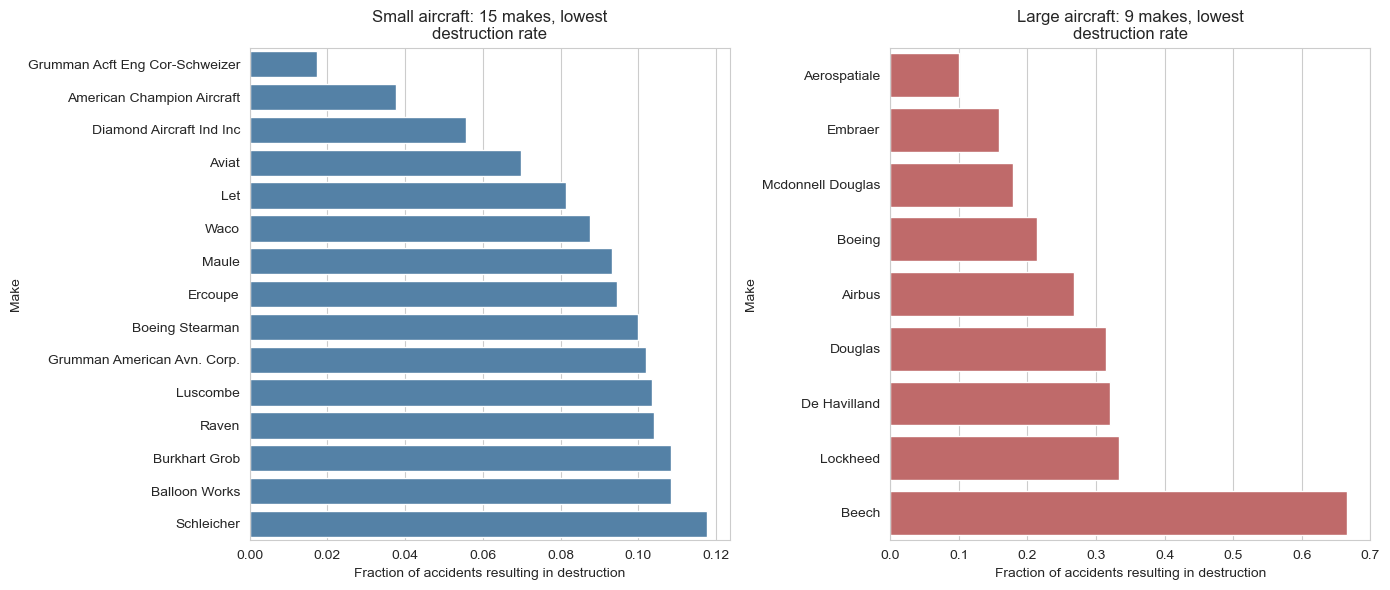

In [7]:
def lowest_destroyed_makes(sub, n=15, min_n=MIN_N):
    g = sub.groupby('Make')['Destroyed'].agg(['mean', 'count'])
    return g[g['count'] >= min_n].sort_values('mean').head(n)

small_destroyed = lowest_destroyed_makes(small)
large_destroyed = lowest_destroyed_makes(large)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_destroyed['mean'], y=small_destroyed.index, ax=axes[0], color='steelblue')
axes[0].set_title('Small aircraft: 15 makes, lowest\ndestruction rate')
axes[0].set_xlabel('Fraction of accidents resulting in destruction')

sns.barplot(x=large_destroyed['mean'], y=large_destroyed.index, ax=axes[1], color='indianred')
axes[1].set_title(f'Large aircraft: {len(large_destroyed)} makes, lowest\ndestruction rate')
axes[1].set_xlabel('Fraction of accidents resulting in destruction')

plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

**Larger planes**

22 large plane types qualify with >= 10 examples


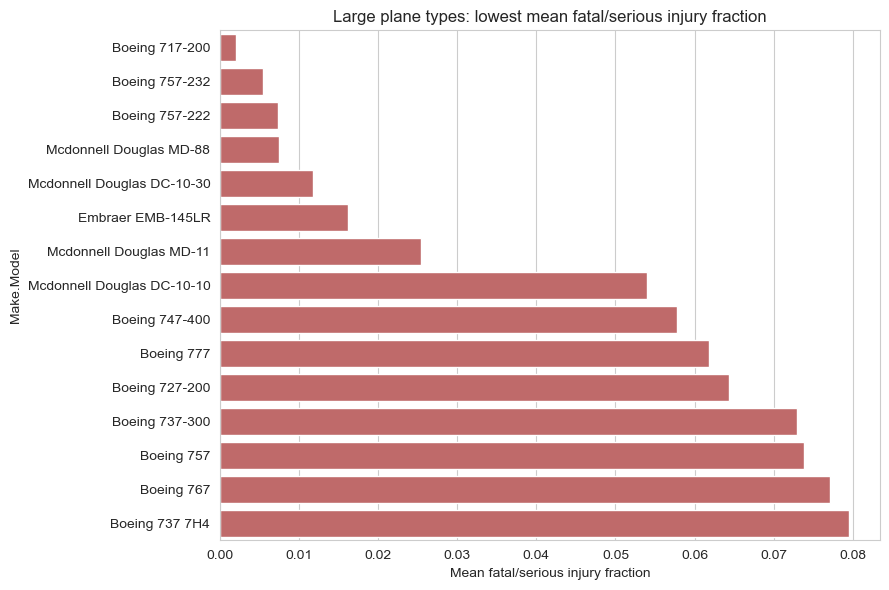

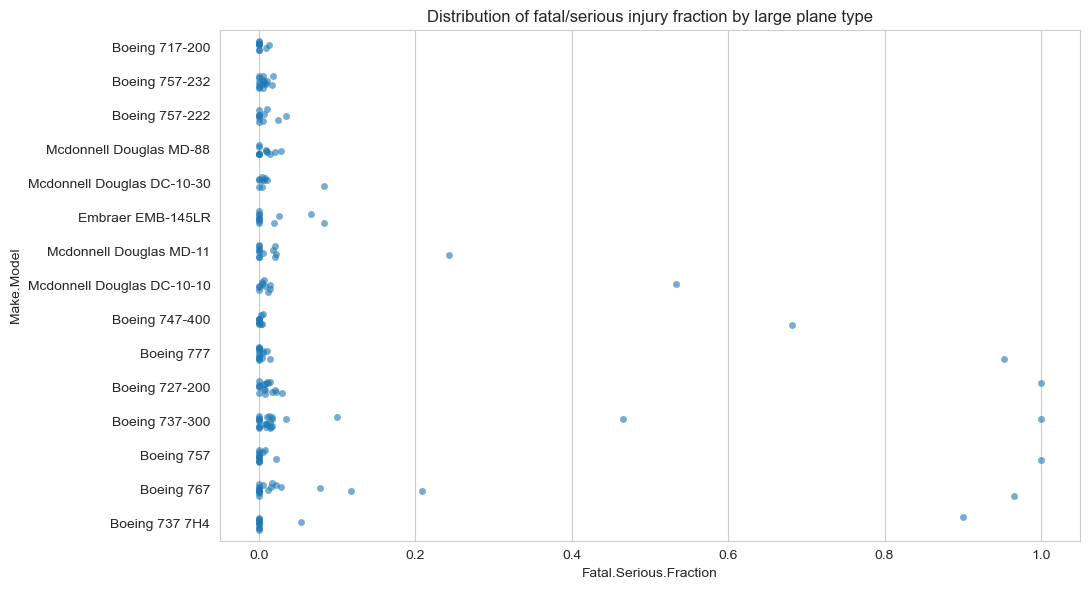

In [8]:
def lowest_injury_models(sub, n=15, min_n=MIN_N):
    g = sub.groupby('Make.Model')['Fatal.Serious.Fraction'].agg(['mean', 'count'])
    return g[g['count'] >= min_n].sort_values('mean')

large_models = lowest_injury_models(large)
print(f'{len(large_models)} large plane types qualify with >= {MIN_N} examples')

top_large_models = large_models.head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=top_large_models['mean'], y=top_large_models.index, color='indianred')
plt.title('Large plane types: lowest mean fatal/serious injury fraction')
plt.xlabel('Mean fatal/serious injury fraction')
plt.tight_layout()
plt.show()

large_top_models_data = large[large['Make.Model'].isin(top_large_models.index)]
plt.figure(figsize=(11, 6))
sns.stripplot(data=large_top_models_data, x='Fatal.Serious.Fraction', y='Make.Model',
              order=top_large_models.index, jitter=0.2, alpha=0.6)
plt.title('Distribution of fatal/serious injury fraction by large plane type')
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

54 small plane types (within the 10 lowest-injury makes) qualify with >= 10 examples


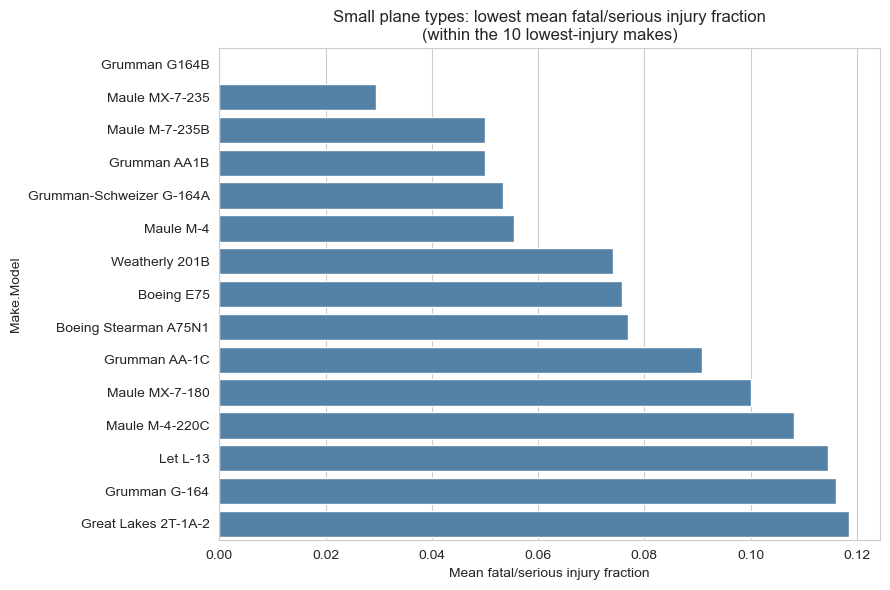

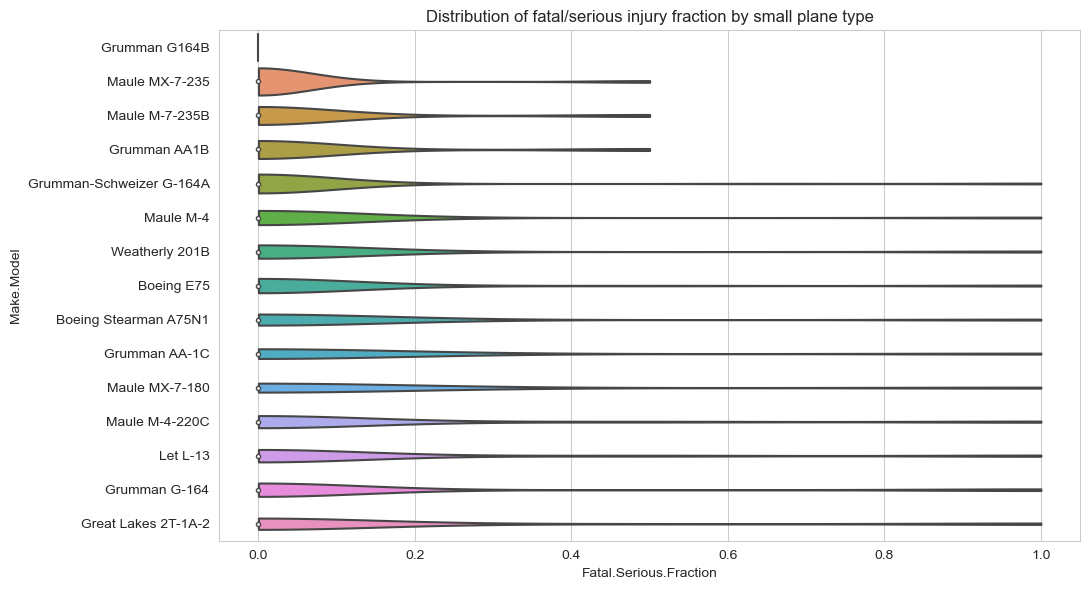

In [9]:
# restrict to the 10 lowest-mean-injury small makes identified earlier, then rank their models
small_top10_data = small[small['Make'].isin(top10_small_makes)]
small_models = lowest_injury_models(small_top10_data)
print(f'{len(small_models)} small plane types (within the 10 lowest-injury makes) qualify with >= {MIN_N} examples')

top_small_models = small_models.head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=top_small_models['mean'], y=top_small_models.index, color='steelblue')
plt.title('Small plane types: lowest mean fatal/serious injury fraction\n(within the 10 lowest-injury makes)')
plt.xlabel('Mean fatal/serious injury fraction')
plt.tight_layout()
plt.show()

small_top_models_data = small_top10_data[small_top10_data['Make.Model'].isin(top_small_models.index)]
plt.figure(figsize=(11, 6))
sns.violinplot(data=small_top_models_data, x='Fatal.Serious.Fraction', y='Make.Model',
               order=top_small_models.index, cut=0)
plt.title('Distribution of fatal/serious injury fraction by small plane type')
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

                  Fatal.Serious.Fraction        Destroyed       
                                    mean  count      mean  count
Weather.Condition                                               
IMC                             0.667418   5016  0.598212   4923
Unknown                         0.639599    771  0.613573    722
VMC                             0.229747  58484  0.173967  57735


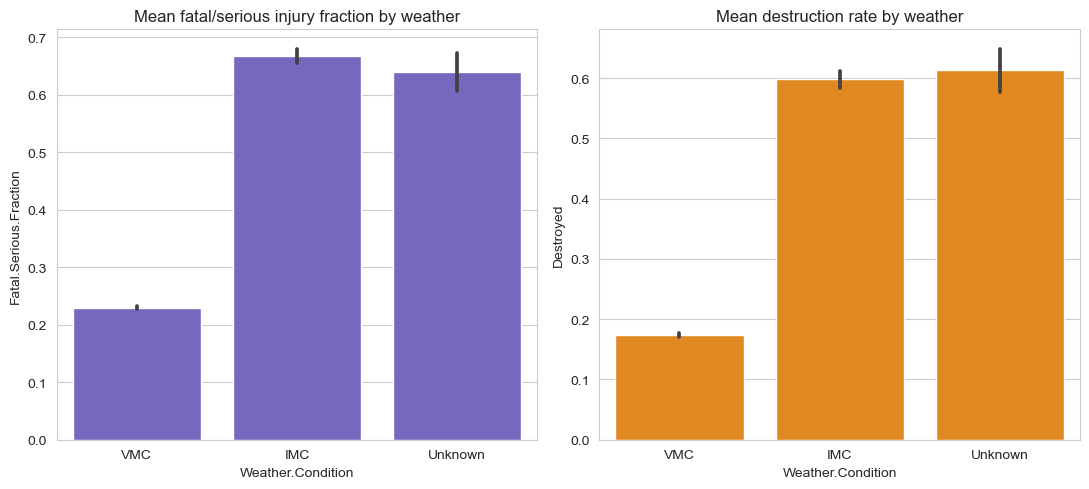


VMC vs IMC fatal/serious fraction: t=-65.84, p=0.00e+00


In [10]:
weather_stats = df.groupby('Weather.Condition')[['Fatal.Serious.Fraction', 'Destroyed']].agg(['mean', 'count'])
print(weather_stats)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sns.barplot(data=df, x='Weather.Condition', y='Fatal.Serious.Fraction',
            order=['VMC', 'IMC', 'Unknown'], ax=axes[0], color='slateblue')
axes[0].set_title('Mean fatal/serious injury fraction by weather')

sns.barplot(data=df, x='Weather.Condition', y='Destroyed',
            order=['VMC', 'IMC', 'Unknown'], ax=axes[1], color='darkorange')
axes[1].set_title('Mean destruction rate by weather')
plt.tight_layout()
plt.show()

vmc = df.loc[df['Weather.Condition'] == 'VMC', 'Fatal.Serious.Fraction'].dropna()
imc = df.loc[df['Weather.Condition'] == 'IMC', 'Fatal.Serious.Fraction'].dropna()
t, p = stats.ttest_ind(vmc, imc, equal_var=False)
print(f'\nVMC vs IMC fatal/serious fraction: t={t:.2f}, p={p:.2e}')

                      Fatal.Serious.Fraction        Destroyed       
                                        mean  count      mean  count
Broad.phase.of.flight                                               
Taxi                                0.023057   1504  0.028807   1458
Landing                             0.041736  12670  0.046214  12572
Standing                            0.150557    733  0.141667    600
Takeoff                             0.230774   9466  0.223422   9444
Go-around                           0.300777   1170  0.290847   1169
Descent                             0.321537   1464  0.323636   1375
Approach                            0.345705   5014  0.293528   4991
Cruise                              0.353042   8064  0.347311   7941
Other                               0.395140     74  0.309859     71
Climb                               0.428547   1497  0.434040   1463
Maneuvering                         0.467014   6224  0.424194   6200
Unknown                           

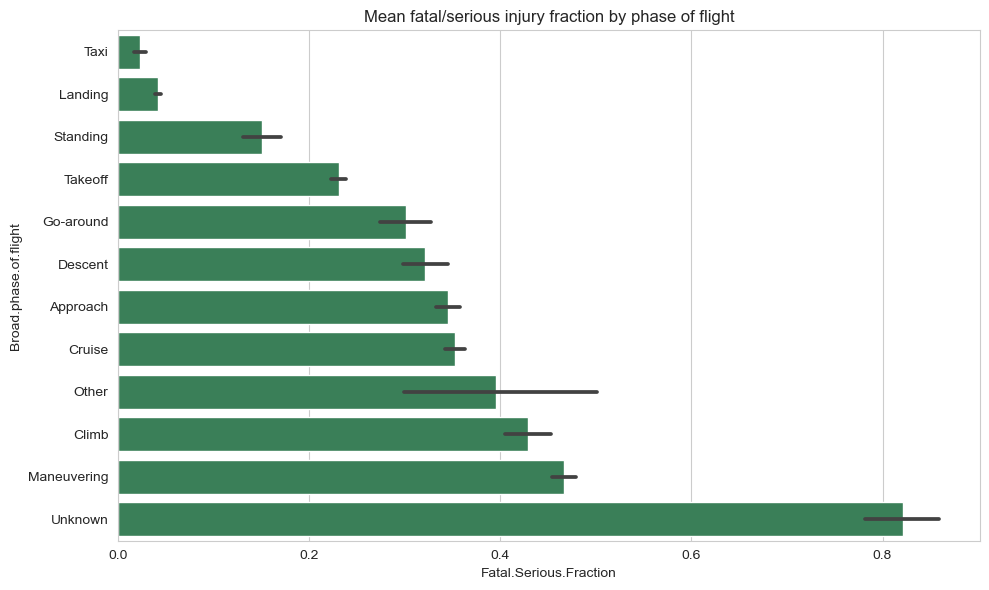


ANOVA across phase of flight: F=758.7, p=0.00e+00


In [11]:
phase_stats = df.groupby('Broad.phase.of.flight')[['Fatal.Serious.Fraction', 'Destroyed']].agg(['mean', 'count'])
phase_order = phase_stats.sort_values(('Fatal.Serious.Fraction', 'mean')).index
print(phase_stats.loc[phase_order])

plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Fatal.Serious.Fraction', y='Broad.phase.of.flight', order=phase_order, color='seagreen')
plt.title('Mean fatal/serious injury fraction by phase of flight')
plt.tight_layout()
plt.show()

phase_groups = [g['Fatal.Serious.Fraction'].dropna() for _, g in df.dropna(subset=['Broad.phase.of.flight']).groupby('Broad.phase.of.flight')]
f, p = stats.f_oneway(*phase_groups)
print(f'\nANOVA across phase of flight: F={f:.1f}, p={p:.2e}')